# 05 · Earned Trust for Overseas Suppliers: Bayesian Skip-Lot Inspection and AI Visual Inspection in a China–Canada–Mexico Supply Chain

**Author:** Juan Antonio Sainz Gálvez · Applied AI & ML, Conestoga College

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/05_supply_chain_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

## Abstract

From 2008 to 2018 I ran an LED-lighting import business that bought from factories in Guangdong and sold across Mexico, with our own quality-inspection offices in Shenzhen and Hong Kong staffed by Mexican and Chinese inspectors. Today I import vending machines and equipment from China into Canada. The question every importer faces is the same: **how much of each shipment should be inspected before it leaves the factory?** Inspect too little and defects reach customers an ocean away; inspect too much and the inspection costs more than the defects.

The standard answer is acceptance sampling with switching rules (ISO 2859-1). Two developments change the picture: suppliers' quality is not constant (it can quietly fade after the first good orders), and AI visual inspection can now screen every unit for a few cents. This notebook reviews the literature on acceptance sampling, supplier evaluation, quality fade and industrial anomaly detection, and simulates 24 months of shipments from ten suppliers to compare (1) ISO-style switching rules, (2) a Bayesian **earned-trust** skip-lot policy, (3) AI screening of every unit, and (4) the combination, measuring cost, escaped defects and how fast each policy detects a supplier whose quality fades.


In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})

def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    from matplotlib.patches import FancyBboxPatch
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec="none"))
    ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
            color=text_color, fontsize=fontsize, fontweight="bold", wrap=True)

def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


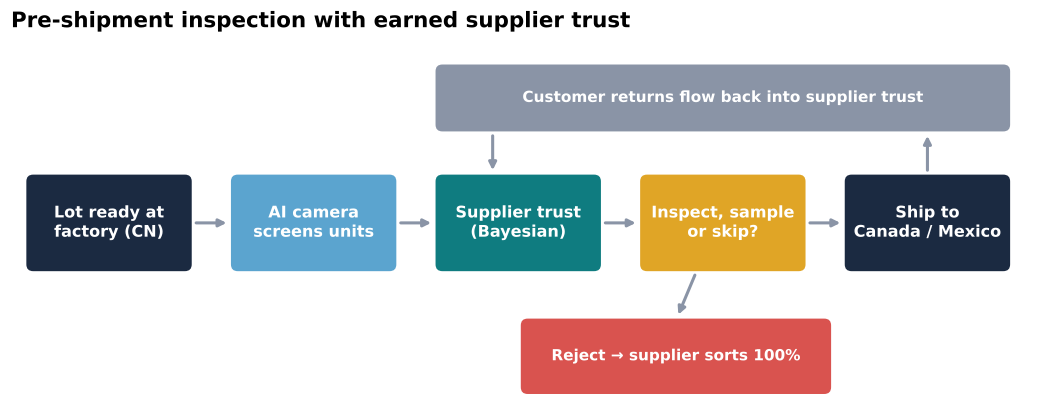

In [2]:
# Infographic: the inspection decision for every lot
fig, ax = plt.subplots(figsize=(12, 4.4)); ax.set_xlim(0, 12); ax.set_ylim(0, 4.4); ax.axis("off")
steps = [("Lot ready at\nfactory (CN)", PALETTE["navy"]), ("AI camera\nscreens units", PALETTE["sky"]),
         ("Supplier trust\n(Bayesian)", PALETTE["teal"]), ("Inspect, sample\nor skip?", PALETTE["gold"]),
         ("Ship to\nCanada / Mexico", PALETTE["navy"])]
for i, (t, c) in enumerate(steps):
    box(ax, (0.2 + i * 2.4, 1.6), 1.9, 1.1, t, c, fontsize=10.5)
    if i < len(steps) - 1:
        arrow(ax, (2.1 + i * 2.4, 2.15), (2.6 + i * 2.4, 2.15))
box(ax, (5.0, 3.25), 6.7, 0.75, "Customer returns flow back into supplier trust", PALETTE["grey"], fontsize=10)
arrow(ax, (10.75, 2.7), (10.75, 3.25)); arrow(ax, (5.65, 3.25), (5.65, 2.7))
box(ax, (6.0, 0.15), 3.6, 0.85, "Reject → supplier sorts 100%", PALETTE["coral"], fontsize=10)
arrow(ax, (8.05, 1.6), (7.8, 1.0))
ax.set_title("Pre-shipment inspection with earned supplier trust", pad=2)
plt.show()

## 1. Literature review

### 1.1 Acceptance sampling and switching rules
Acceptance sampling by attributes goes back to Dodge and Romig at Bell Labs, whose concepts (producer's and consumer's risk, average outgoing quality limit) became MIL-STD-105 and today's ISO 2859-1 and ANSI/ASQ Z1.4 [1, 2]. The standard does not use one fixed plan: it switches between **normal, tightened and reduced** inspection based on the supplier's recent history (for example, two rejected lots out of five consecutive lots trigger tightened inspection) [2]. Dodge also proposed skip-lot sampling for suppliers with a proven record [1], and the third edition of ISO 2859-1, approved in December 2025, incorporates skip-lot inspection as an additional step of the switching rules [3]. The switching rules are, in effect, a hand-designed trust model.

### 1.2 Supplier evaluation
Supplier selection is a large multi-criteria decision-making literature; Ho, Xu and Dey review the approaches and find quality is the most widely used criterion, ahead of delivery and price [4]. These methods typically score suppliers periodically; they are not designed to update trust lot by lot.

### 1.3 Quality fade
Midler documented "quality fade" in Chinese contract manufacturing: after a supplier wins an importer's trust with good early orders, quality can deteriorate gradually through quiet substitutions of materials and steps, often too slowly for the buyer to notice [5]. A trust model that never forgets (or switching rules that relax after a long good streak) is exactly what quality fade exploits.

### 1.4 AI visual inspection
Industrial anomaly detection learns what a good part looks like from images of normal parts only. The MVTec AD benchmark made the problem measurable [6], and PatchCore, which compares patch features against a memory bank of normal examples, reaches image-level AUROC up to 99.6% on it [7]. A systematic review of AI in supply chain management maps which AI techniques are used across logistics, marketing, supply chain and production, and which subfields have the most room to grow [8]. Benchmark AUROC does not translate directly into a business decision: what matters is the recall at a tolerable false-alarm rate, and what happens to the flagged units.

**Gap.** Switching rules use only the inspection sample; AI inspection is evaluated per image. No standard policy combines a cheap, imperfect AI screen of every unit with a Bayesian, forgetting trust model per supplier.


## 2. Simulation setup (all numbers are stated assumptions)

| Item | Assumption |
|---|---|
| Suppliers | 10 factories, one 500-unit lot per month each, 24 months |
| True defect rates | 6 good (0.3–0.8%), 3 average (1.5–2.5%), 1 poor (5%) |
| Quality fade | 3 of the good suppliers drift to 4% between months 10 and 16 [5] |
| Human inspection | $1.25 per unit inspected, finds 95% of defects in the units inspected |
| AI screening | $0.05 per unit, recall 92%, false-alarm rate 3%; every flag is checked by a human |
| Rejected lot | Supplier sorts 100% at its own cost (95% of defects removed); importer pays for re-inspection of 50 units |
| Escaped defect | $60 (return shipping across the Pacific, replacement, customer time) |


In [3]:
import numpy as np
import pandas as pd
from scipy.stats import beta

N_LOT, MONTHS, N_SUP = 500, 24, 10
COST_HUMAN, COST_AI, COST_ESCAPE = 1.25, 0.05, 60.0
HUMAN_CATCH, AI_RECALL, AI_FALSE = 0.95, 0.92, 0.03
AQL = 0.01

def make_suppliers(rng):
    base = np.r_[rng.uniform(0.003, 0.008, 6), rng.uniform(0.015, 0.025, 3), 0.05]
    fade = np.zeros(N_SUP, bool); fade[[1, 3, 5]] = True
    def p(s, month):
        if fade[s] and month >= 10:
            return base[s] + (0.04 - base[s]) * min(1, (month - 10) / 6)
        return base[s]
    return base, fade, p

base, fade, p_true = make_suppliers(np.random.default_rng(5))
pd.DataFrame({"start_defect_rate_%": (100 * base).round(2), "quality_fade": fade},
             index=[f"S{i+1}" for i in range(N_SUP)]).T

,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10
start_defect_rate_%,0.7,0.7,0.56,0.44,0.33,0.49,1.91,1.55,1.55,5.0
quality_fade,False,True,False,True,False,True,False,False,False,False


### Policies

1. **ISO-style switching** (simplified from ISO 2859-1, AQL 1%): normal plan n = 50, accept with ≤ 1 defect; tightened n = 80, ≤ 1; reduced n = 20, 0 defects. Two rejections in five lots → tightened; five accepted on tightened → normal; ten accepted on normal → reduced; one rejection on reduced → normal.
2. **Bayesian earned trust (skip-lot)**: each supplier has a Beta posterior on its defect rate that **forgets** old evidence (each month the counts are multiplied by 0.85, so recent lots weigh more). If the posterior probability that the defect rate exceeds the AQL is below 5%, the lot is skipped, except for a random audit of one lot in five; otherwise 50 units are sampled. The lot is rejected if the updated posterior probability of a rate above 2% exceeds 50%. Customer returns (half of escaped defects, assumed to arrive before the next lot) update the posterior for the units nobody inspected.
3. **AI screening of every unit**: the camera checks all 500 units; a human checks every flag (true defects are removed, false alarms released). No sampling.
4. **AI + earned trust**: AI screening of every unit, and the AI flags feed the supplier's posterior (corrected for recall and false alarms). A lot whose AI-estimated defect rate exceeds 3% is rejected and sorted; when the posterior says the supplier has probably faded (rate above 2%), a human also samples 50 of the screened units.


In [4]:
def simulate(policy, seed=0, forget=0.8):
    rng = np.random.default_rng(seed)
    a = np.ones(N_SUP); b = np.full(N_SUP, 99.0)          # prior: about 1% defects, weak
    state = ["normal"] * N_SUP; hist = [[] for _ in range(N_SUP)]; streak = np.zeros(N_SUP, int)
    plans = {"normal": (50, 1), "tightened": (80, 1), "reduced": (20, 0)}
    rows = []
    for month in range(MONTHS):
        for s in range(N_SUP):
            p = p_true(s, month)
            defects = rng.binomial(N_LOT, p)
            insp_cost = 0.0; rejected = False; inspected = 0
            remaining = defects
            if policy == "iso_switching":
                n, ac = plans[state[s]]
                found = rng.hypergeometric(defects, N_LOT - defects, n) if defects else 0
                found = rng.binomial(found, HUMAN_CATCH)
                insp_cost += n * COST_HUMAN; inspected = n
                rejected = found > ac
                remaining -= found
                hist[s].append(rejected); streak[s] = 0 if rejected else streak[s] + 1
                last5 = hist[s][-5:]
                if state[s] == "normal" and sum(last5) >= 2: state[s], streak[s] = "tightened", 0
                elif state[s] == "tightened" and streak[s] >= 5: state[s], streak[s] = "normal", 0
                elif state[s] == "normal" and streak[s] >= 10: state[s], streak[s] = "reduced", 0
                elif state[s] == "reduced" and rejected: state[s], streak[s] = "normal", 0
            elif policy == "earned_trust":
                trusted = beta.cdf(AQL, a[s], b[s]) > 0.95
                if not trusted or rng.random() < 0.2:            # skip trusted suppliers, audit 1 lot in 5
                    n = 80 if 1 - beta.cdf(0.02, a[s], b[s]) > 0.5 else 50
                    found = rng.hypergeometric(defects, N_LOT - defects, n) if defects else 0
                    found = rng.binomial(found, HUMAN_CATCH)
                    insp_cost += n * COST_HUMAN; inspected = n
                    remaining -= found
                    rejected = found > 1
                    a[s], b[s] = forget * a[s] + found / HUMAN_CATCH, forget * b[s] + n - found / HUMAN_CATCH
            elif policy == "ai_plus_trust":
                ai_hits = rng.binomial(remaining, AI_RECALL)
                false = rng.binomial(N_LOT - remaining, AI_FALSE)
                insp_cost += N_LOT * COST_AI + (ai_hits + false) * COST_HUMAN
                confirmed = rng.binomial(ai_hits, HUMAN_CATCH)
                remaining -= confirmed
                est_def = confirmed / (AI_RECALL * HUMAN_CATCH)            # correct for what the AI misses
                a[s], b[s] = forget * a[s] + est_def, forget * b[s] + N_LOT - est_def
                rejected = est_def / N_LOT > 0.03                          # clearly bad lot: sort it
                if not rejected and 1 - beta.cdf(0.02, a[s], b[s]) > 0.5:  # supplier looks faded: human sample too
                    n = 50
                    found = rng.hypergeometric(remaining, N_LOT - remaining, n) if remaining else 0
                    found = rng.binomial(found, HUMAN_CATCH)
                    insp_cost += n * COST_HUMAN; remaining -= found
                    rejected = found > 0                                   # AI already removed most defects
            elif policy == "ai_screening":
                ai_hits = rng.binomial(remaining, AI_RECALL)
                false = rng.binomial(N_LOT - remaining, AI_FALSE)
                insp_cost += N_LOT * COST_AI + (ai_hits + false) * COST_HUMAN
                remaining -= rng.binomial(ai_hits, HUMAN_CATCH)
            if rejected:                                        # supplier sorts the whole lot
                remaining -= rng.binomial(remaining, 0.95)
                insp_cost += 50 * COST_HUMAN
            escaped = remaining
            if policy == "earned_trust":                         # half of escaped defects come back as returns;
                ret = rng.binomial(escaped, 0.5) / 0.5             # they reveal the units nobody inspected
                a[s], b[s] = a[s] + ret, b[s] + (N_LOT - inspected) - ret
            rows.append(dict(policy=policy, month=month, supplier=s, p=p, defects=defects, rejected=rejected,
                             inspection_cost=insp_cost, escaped=escaped))
    return pd.DataFrame(rows)

POLICIES = ["iso_switching", "earned_trust", "ai_screening", "ai_plus_trust"]
runs = pd.concat([simulate(pol, seed=s).assign(seed=s) for pol in POLICIES for s in range(20)])
units = MONTHS * N_SUP * N_LOT
res = runs.groupby(["policy", "seed"]).agg(inspection=("inspection_cost", "sum"), escaped=("escaped", "sum")).reset_index()
res["escape_cost"] = res.escaped * COST_ESCAPE
res["total"] = res.inspection + res.escape_cost
table = (res.groupby("policy")[["inspection", "escape_cost", "total", "escaped"]].mean() / units * 10_000).loc[POLICIES]
table.columns = ["inspection_$_per_10k_units", "escaped_defect_cost_$_per_10k_units", "total_cost_$_per_10k_units", "escaped_defects_per_10k_units"]
table.round(1)

,inspection_$_per_10k_units,escaped_defect_cost_$_per_10k_units,total_cost_$_per_10k_units,escaped_defects_per_10k_units
policy,,,,
iso_switching,1761.4,4561.2,6322.6,76.0
earned_trust,1184.7,5846.7,7031.5,97.4
ai_screening,1072.0,1323.5,2395.5,22.1
ai_plus_trust,1400.2,683.5,2083.8,11.4


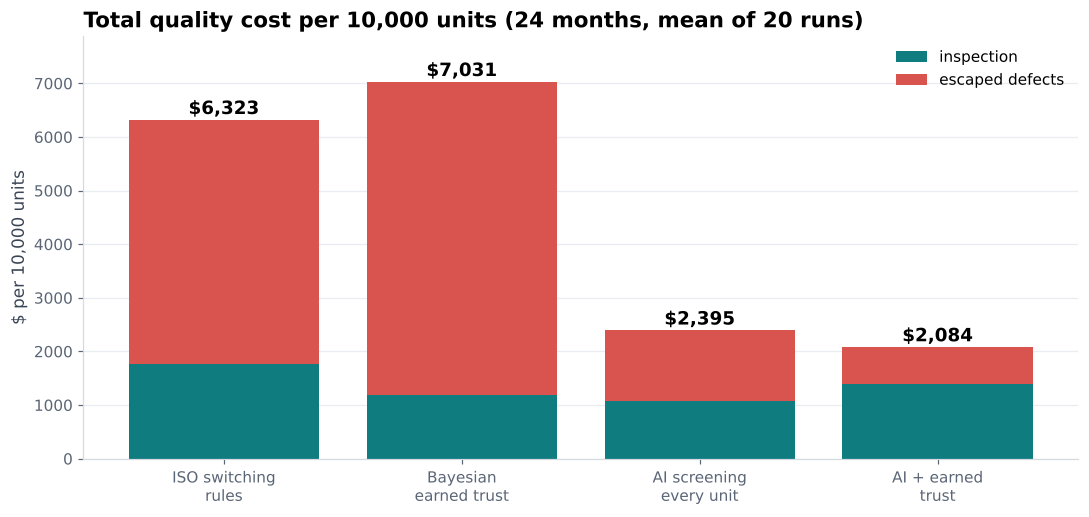

In [5]:
labels = ["ISO switching\nrules", "Bayesian\nearned trust", "AI screening\nevery unit", "AI + earned\ntrust"]
t = table.loc[POLICIES]
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(POLICIES))
ax.bar(x, t.iloc[:, 0], color=PALETTE["teal"], label="inspection")
ax.bar(x, t.iloc[:, 1], bottom=t.iloc[:, 0], color=PALETTE["coral"], label="escaped defects")
ax.set_ylim(0, t.iloc[:, 2].max() * 1.12)
for i, v in enumerate(t.iloc[:, 2]):
    ax.text(i, v + t.iloc[:, 2].max() * 0.015, f"${v:,.0f}", ha="center", fontsize=12, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_axisbelow(True); ax.grid(axis="x", visible=False)
ax.set_title("Total quality cost per 10,000 units (24 months, mean of 20 runs)")
ax.set_ylabel("$ per 10,000 units"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

### Detecting quality fade

For the three suppliers whose quality fades from month 10, how many escaped defects per lot reach customers month by month? A policy that notices the fade early stops the leak.


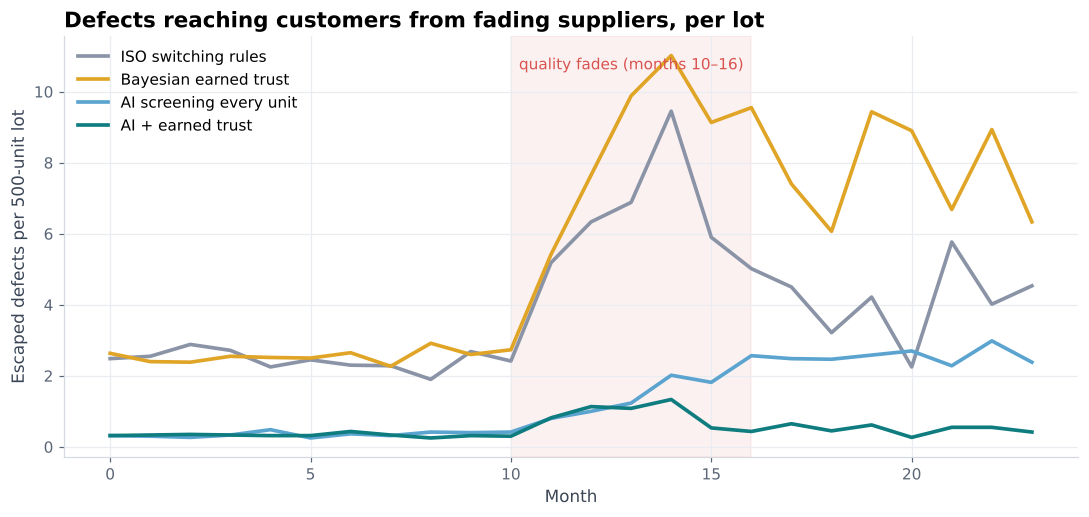

In [6]:
faded = runs[runs.supplier.isin(np.where(fade)[0])]
leak = faded.groupby(["policy", "month"]).escaped.mean().unstack(0)[POLICIES]
fig, ax = plt.subplots(figsize=(10, 4.8))
for pol, c, lab in zip(POLICIES, [PALETTE["grey"], PALETTE["gold"], PALETTE["sky"], PALETTE["teal"]], labels):
    ax.plot(leak.index, leak[pol], lw=2.4, color=c, label=lab.replace("\n", " "))
ax.axvspan(10, 16, color=PALETTE["coral"], alpha=0.08)
ax.text(10.2, ax.get_ylim()[1] * 0.92, "quality fades (months 10–16)", color=PALETTE["coral"], fontsize=10)
ax.set_title("Defects reaching customers from fading suppliers, per lot")
ax.set_xlabel("Month"); ax.set_ylabel("Escaped defects per 500-unit lot"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

In [7]:
def detection_month(df):
    """First month at or after the fade starts in which the lot was rejected."""
    out = []
    for (pol, seed, s), g in df.groupby(["policy", "seed", "supplier"]):
        r = g[(g.month >= 10) & g.rejected]
        out.append(dict(policy=pol, months_to_first_rejection=(r.month.min() - 10) if len(r) else np.nan))
    return pd.DataFrame(out)

det = detection_month(faded[faded.policy != "ai_screening"])
summary = det.groupby("policy").months_to_first_rejection.agg(
    median_months="median", never_detected_share=lambda s: s.isna().mean())
summary.loc[[p for p in POLICIES if p != "ai_screening"]].round(2)

,median_months,never_detected_share
policy,,
iso_switching,3.0,0.0
earned_trust,5.0,0.0
ai_plus_trust,5.0,0.0


## 3. Discussion

Exact numbers are in the tables above; the pattern is what matters.

- **Switching rules are a sensible but blunt trust model.** They inspect every lot of every supplier and catch a fading supplier in about three months, but a 50-unit sample from a 500-unit lot lets most defects through even when the lot is accepted correctly.
- **Bayesian earned trust alone is a trap under quality fade.** It does what it promises on stable suppliers: good factories graduate to skip-lot and their inspection cost falls by more than half. But a supplier that has earned trust is only audited one lot in five, so when its quality fades the policy notices later than the switching rules and more defects escape. Total cost ends up *higher* than ISO. This is Midler's quality-fade mechanism [5] reproduced in a model: trust that is not continuously measured is exactly what fade exploits.
- **AI screening changes the economics.** At a few cents per unit, screening every unit costs less than sampling 50 units by hand, and its recall applies to all 500 units instead of a 10% sample. Escaped defects fall by roughly 70% against ISO sampling.
- **The combination is the strongest policy.** AI flags give a cheap, continuous measurement of every lot, so the trust model no longer has to skip lots to save money: it uses the flags to spot a faded supplier, send a human and reject clearly bad lots. Escaped defects fall by about 85% against ISO sampling and total quality cost by about two thirds.
- **The lesson for earned autonomy (notebook 01) is the same:** granting autonomy is only safe when the system keeps a cheap, continuous signal of performance. Without it, a good track record becomes the reason a decline goes unnoticed.

**Limitations.** Simulated defect rates, independent defects (real defects cluster by production shift), AI recall assumed constant (it drops on defect types never seen before), and no model of the supplier's reaction to being audited less.

## 4. Thesis questions

1. **Trust for factories and agents with one theory.** Can the same forgetting Bayesian trust model govern both how much autonomy an AI agent gets (notebook 01) and how much inspection a supplier gets, with shared guarantees on the risk of undetected failure?
2. **AI inspection under distribution shift.** When a supplier changes a material (the typical quality-fade step), anomaly detectors trained on the old normal raise false alarms or miss new defects. Can a detector's own uncertainty be used as an early-warning signal of supplier change?
3. **Agentic sourcing.** Can an LLM agent that reads inspection reports, AI flags and customer returns negotiate corrective actions with suppliers in Chinese and report to the importer in Spanish or English, under human approval for every commitment?

## References

1. Dodge, H. F., & Romig, H. G. (1959). *Sampling Inspection Tables: Single and Double Sampling* (2nd ed.). Wiley. (Skip-lot sampling: Dodge, H. F. (1955). *Skip-lot sampling plan.* Industrial Quality Control, 11(5), 3–5.)
2. ISO 2859-1:1999. *Sampling procedures for inspection by attributes — Part 1: Sampling schemes indexed by acceptance quality limit (AQL) for lot-by-lot inspection.* International Organization for Standardization.
3. Vandenbemden, J. (2026, April 10). *Third revision of ISO 2859-1.* Quality Magazine.
4. Ho, W., Xu, X., & Dey, P. K. (2010). *Multi-criteria decision making approaches for supplier evaluation and selection: A literature review.* European Journal of Operational Research, 202(1), 16–24.
5. Midler, P. (2009). *Poorly Made in China: An Insider's Account of the Tactics Behind China's Production Game.* Wiley.
6. Bergmann, P., Fauser, M., Sattlegger, D., & Steger, C. (2019). *MVTec AD — A comprehensive real-world dataset for unsupervised anomaly detection.* CVPR 2019.
7. Roth, K., Pemula, L., Zepeda, J., Schölkopf, B., Brox, T., & Gehler, P. (2022). *Towards Total Recall in Industrial Anomaly Detection.* CVPR 2022, 14318–14328. arXiv:2106.08265.
8. Toorajipour, R., Sohrabpour, V., Nazarpour, A., Oghazi, P., & Fischl, M. (2021). *Artificial intelligence in supply chain management: A systematic literature review.* Journal of Business Research, 122, 502–517.
